# 4. Comparación con líneas base (test, protocolo común)

- **Protocolo:** sesiones de 20 recomendaciones sin repetición; cada rating se revela recién al mostrar el ítem.
- **Métricas:** retorno normalizado (principal), hit rate y NDCG@10 del primer paso.
- **Condiciones:** grupo visible, grupo oculto (cold-start estricto) y warm-up de 5 ítems (no es cold-start).
- **Usuarios y presupuesto:** todas las políticas usan los mismos 1.600 usuarios de test, el mismo catálogo y el mismo presupuesto, con 3 semillas de evaluación.
- **Modelos:** 3 semillas de entrenamiento cada uno.
- **Selección:** hecha antes, en validación (notebooks 02 y 03). Test se usó una sola vez.

**Formato de cada celda:** media entre semillas de entrenamiento ± desvío entre semillas [± IC 95 % por usuario].
- El **desvío entre semillas** mide la variabilidad del **entrenamiento**.
- El **IC por usuario** mide la variabilidad de la **evaluación**.
- Las líneas base no se entrenan con semillas: sólo tienen IC.

**Líneas base:** `random` (el 0), `popularity`, `item_mean` (la línea base mínima exigida), `group_mean` (personalizada por segmento) y `group_posterior` (personalizada: infiere el grupo con los ratings vistos).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from src.utils import OUTPUTS
from src import reporte
pd.set_option("display.width", 200)

## 4.1 Retorno normalizado

In [2]:
display(reporte.main_table("random", "normalized"))

condición,visible,oculto,"warm-up 5, visible","warm-up 5, oculto"
policy,,,,
random,-0.002 [±0.005],-0.002 [±0.005],0.003 [±0.006],0.003 [±0.006]
popularity,-0.058 [±0.007],-0.058 [±0.007],-0.117 [±0.009],-0.117 [±0.009]
item_mean,0.689 [±0.005],0.689 [±0.005],0.705 [±0.005],0.705 [±0.005]
group_mean,0.742 [±0.005],0.689 [±0.005],0.749 [±0.005],0.705 [±0.005]
group_posterior,0.742 [±0.005],0.707 [±0.005],0.749 [±0.005],0.729 [±0.005]
dt,0.655 ± 0.020 [±0.006],0.657 ± 0.018 [±0.005],0.662 ± 0.027 [±0.006],0.667 ± 0.025 [±0.006]
iql_pi,0.697 ± 0.002 [±0.006],0.631 ± 0.029 [±0.006],0.704 ± 0.001 [±0.006],0.666 ± 0.028 [±0.006]
iql_maxq,0.705 ± 0.004 [±0.005],0.616 ± 0.008 [±0.005],0.713 ± 0.004 [±0.005],0.652 ± 0.008 [±0.005]
iql_pi_gamma0.0,0.700 ± 0.004 [±0.006],0.625 ± 0.024 [±0.006],0.701 ± 0.003 [±0.007],0.672 ± 0.017 [±0.005]


## 4.2 Métricas secundarias

In [3]:
for metric in ["hit_rate", "ndcg@10", "return"]:
    print(f"\n=== {metric} ===")
    display(reporte.main_table("random", metric))


=== hit_rate ===


condición,visible,oculto,"warm-up 5, visible","warm-up 5, oculto"
policy,,,,
random,0.459 [±0.010],0.459 [±0.010],0.463 [±0.010],0.463 [±0.010]
popularity,0.429 [±0.009],0.429 [±0.009],0.396 [±0.009],0.396 [±0.009]
item_mean,0.894 [±0.006],0.894 [±0.006],0.904 [±0.006],0.904 [±0.006]
group_mean,0.918 [±0.006],0.894 [±0.006],0.923 [±0.006],0.904 [±0.006]
group_posterior,0.918 [±0.006],0.896 [±0.006],0.923 [±0.006],0.911 [±0.006]
dt,0.865 ± 0.015 [±0.007],0.867 ± 0.014 [±0.007],0.871 ± 0.019 [±0.007],0.873 ± 0.019 [±0.007]
iql_pi,0.882 ± 0.001 [±0.007],0.839 ± 0.020 [±0.007],0.886 ± 0.002 [±0.007],0.863 ± 0.019 [±0.007]
iql_maxq,0.902 ± 0.004 [±0.006],0.838 ± 0.006 [±0.007],0.908 ± 0.004 [±0.006],0.865 ± 0.005 [±0.006]
iql_pi_gamma0.0,0.883 ± 0.004 [±0.007],0.836 ± 0.016 [±0.007],0.882 ± 0.003 [±0.007],0.869 ± 0.011 [±0.006]



=== ndcg@10 ===


condición,visible,oculto,"warm-up 5, visible","warm-up 5, oculto"
policy,,,,
random,0.459 [±0.010],0.459 [±0.010],0.459 [±0.010],0.459 [±0.010]
popularity,0.412 [±0.010],0.412 [±0.010],0.411 [±0.010],0.411 [±0.010]
item_mean,0.924 [±0.006],0.924 [±0.006],0.923 [±0.006],0.923 [±0.006]
group_mean,0.936 [±0.006],0.924 [±0.006],0.936 [±0.006],0.923 [±0.006]
group_posterior,0.936 [±0.006],0.924 [±0.006],0.936 [±0.006],0.927 [±0.006]
dt,0.896 ± 0.018 [±0.007],0.880 ± 0.017 [±0.008],0.893 ± 0.022 [±0.007],0.893 ± 0.022 [±0.007]
iql_pi,0.877 ± 0.004 [±0.008],0.850 ± 0.018 [±0.009],0.893 ± 0.003 [±0.008],0.881 ± 0.011 [±0.007]
iql_maxq,0.913 ± 0.005 [±0.006],0.906 ± 0.009 [±0.006],0.916 ± 0.002 [±0.006],0.904 ± 0.009 [±0.006]
iql_pi_gamma0.0,0.886 ± 0.002 [±0.008],0.890 ± 0.005 [±0.007],0.895 ± 0.006 [±0.008],0.899 ± 0.008 [±0.007]



=== return ===


condición,visible,oculto,"warm-up 5, visible","warm-up 5, oculto"
policy,,,,
random,64.298 [±0.582],64.298 [±0.582],48.362 [±0.442],48.362 [±0.442]
popularity,62.726 [±0.570],62.726 [±0.570],45.710 [±0.420],45.710 [±0.420]
item_mean,88.421 [±0.312],88.421 [±0.312],66.735 [±0.234],66.735 [±0.234]
group_mean,90.066 [±0.311],88.421 [±0.312],67.767 [±0.233],66.735 [±0.234]
group_posterior,90.066 [±0.311],88.894 [±0.313],67.767 [±0.233],67.271 [±0.228]
dt,87.098 ± 0.730 [±0.356],87.193 ± 0.702 [±0.353],65.534 ± 0.745 [±0.270],65.655 ± 0.719 [±0.265]
iql_pi,88.237 ± 0.115 [±0.374],85.894 ± 1.099 [±0.391],66.336 ± 0.081 [±0.284],65.398 ± 0.764 [±0.283]
iql_maxq,89.031 ± 0.147 [±0.309],85.710 ± 0.287 [±0.338],66.999 ± 0.106 [±0.232],65.361 ± 0.142 [±0.238]
iql_pi_gamma0.0,88.277 ± 0.163 [±0.384],85.770 ± 0.876 [±0.365],66.201 ± 0.114 [±0.297],65.638 ± 0.443 [±0.259]


## 4.3 Por grupo (grupo oculto, warm-up 0)

In [4]:
display(reporte.group_table("random", ["item_mean", "group_mean", "group_posterior", "dt", "iql_pi", "iql_maxq"], 0, False))
print("Grupo visible, warm-up 0:")
display(reporte.group_table("random", ["item_mean", "group_mean", "group_posterior", "dt", "iql_pi", "iql_maxq"], 0, True))

group,0,1,2,3,4,5,6,7
policy,,,,,,,,
dt,0.749,0.691,0.604,0.605,0.693,0.707,0.671,0.539
group_mean,0.772,0.714,0.637,0.647,0.714,0.735,0.697,0.593
group_posterior,0.769,0.728,0.638,0.651,0.801,0.734,0.727,0.605
iql_maxq,0.655,0.629,0.594,0.582,0.720,0.601,0.618,0.527
iql_pi,0.713,0.655,0.602,0.542,0.779,0.603,0.657,0.496
item_mean,0.772,0.714,0.637,0.647,0.714,0.735,0.697,0.593


Grupo visible, warm-up 0:


group,0,1,2,3,4,5,6,7
policy,,,,,,,,
dt,0.748,0.686,0.603,0.602,0.690,0.710,0.666,0.533
group_mean,0.793,0.767,0.679,0.683,0.854,0.780,0.767,0.616
group_posterior,0.793,0.767,0.679,0.683,0.854,0.780,0.767,0.616
iql_maxq,0.750,0.742,0.662,0.666,0.731,0.762,0.736,0.595
iql_pi,0.784,0.741,0.653,0.613,0.821,0.692,0.737,0.538
item_mean,0.772,0.714,0.637,0.647,0.714,0.735,0.697,0.593


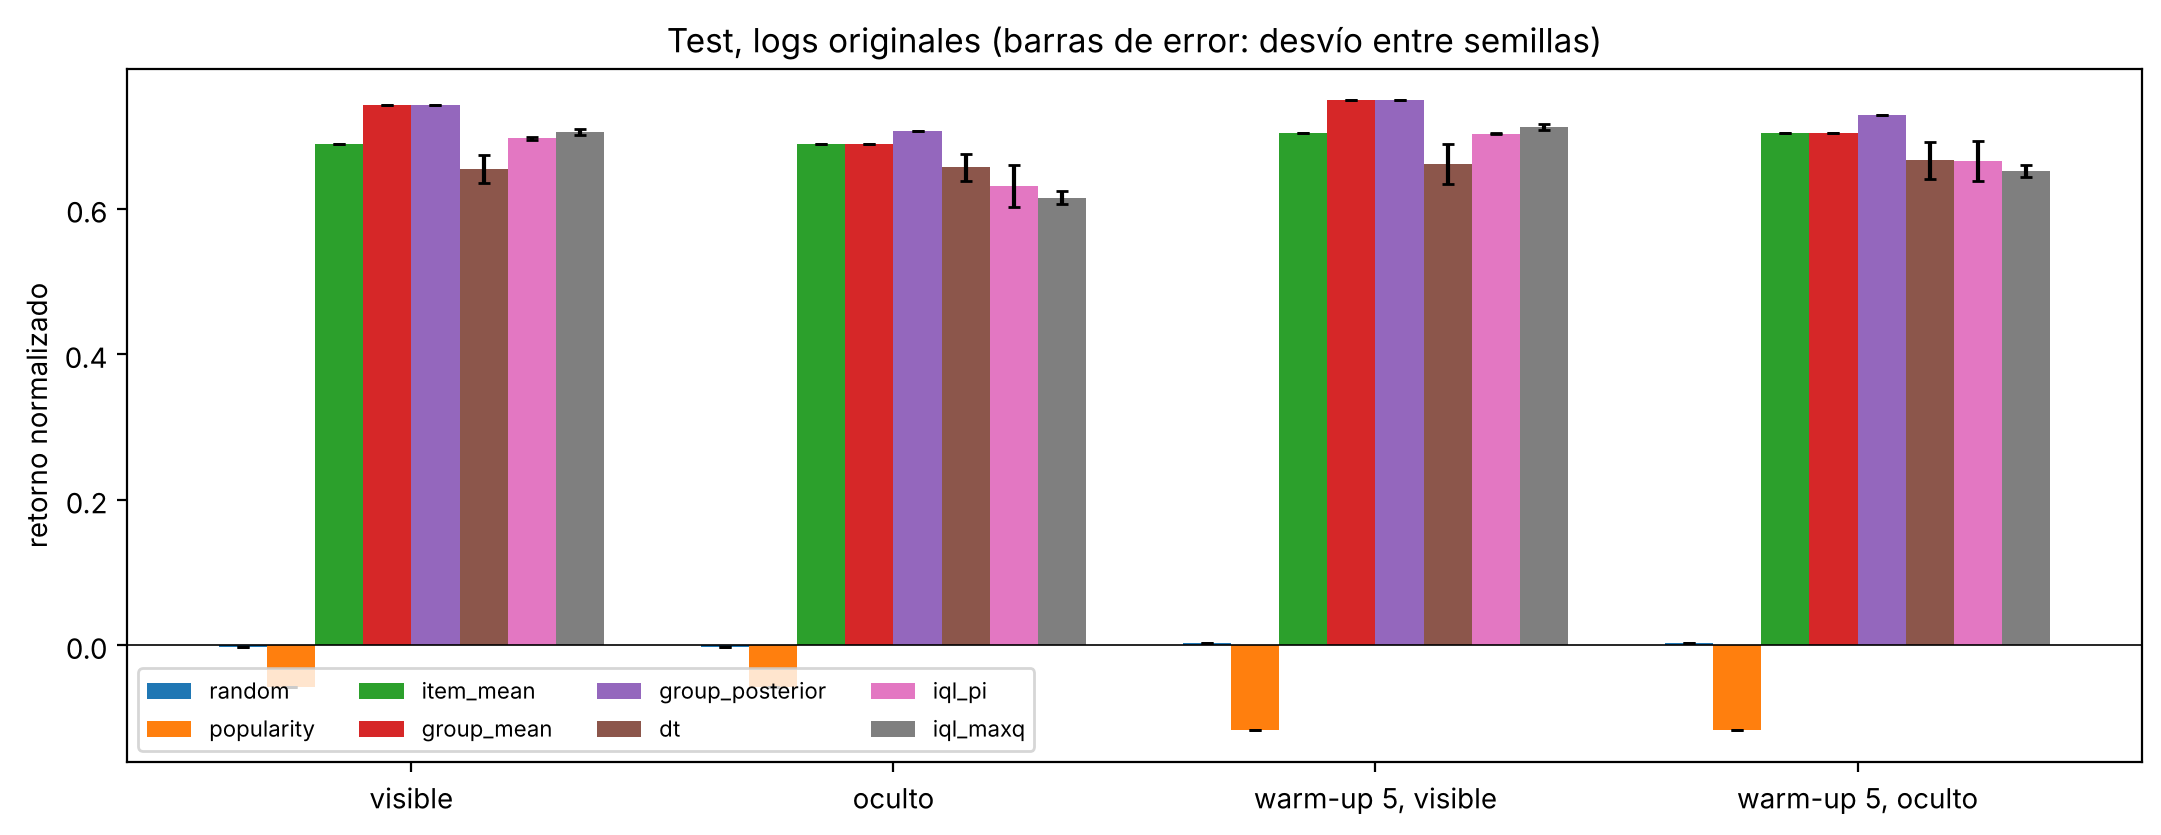

In [5]:
t = reporte.main_table("random", fmt=False)
pols = ["random", "popularity", "item_mean", "group_mean", "group_posterior", "dt", "iql_pi", "iql_maxq"]
conds = list(reporte.COND_LABELS.values())
fig, ax = plt.subplots(figsize=(13, 4.5))
w = 0.1
for i, p in enumerate(pols):
    sub = t[t.policy == p].set_index("condición").loc[conds]
    ax.bar(np.arange(4) + i * w, sub.media, w, yerr=sub.desvío_semillas.fillna(0), label=p, capsize=2)
ax.set_xticks(np.arange(4) + 3.5 * w, conds); ax.set_ylabel("retorno normalizado"); ax.axhline(0, color="k", lw=0.6)
ax.legend(ncol=4, fontsize=8); ax.set_title("Test, logs originales (barras de error: desvío entre semillas)"); plt.show()

## 4.4 Diferencias frente a las líneas base

Una diferencia menor que la dispersión entre semillas **no** es una mejora. La tabla compara cada modelo con `item_mean` (sin personalización) y con `group_posterior` (la línea base personalizada más fuerte).

In [6]:
t = reporte.main_table("random", fmt=False).set_index(["policy", "condición"])
rows = []
for m in ["dt", "iql_pi", "iql_maxq"]:
    for c in conds:
        r = t.loc[(m, c)]
        for b in ["item_mean", "group_posterior"]:
            d = r.media - t.loc[(b, c)].media
            rows.append({"modelo": m, "condición": c, "vs": b, "diferencia": round(d, 3),
                         "desvío semillas": round(r.desvío_semillas, 3),
                         "¿mejora?": "sí" if d > max(r.desvío_semillas, r.ic95_usuarios) else ("no (empata)" if abs(d) <= max(r.desvío_semillas, r.ic95_usuarios) else "no (peor)")})
display(pd.DataFrame(rows).pivot_table(index=["modelo", "vs"], columns="condición", values="¿mejora?", aggfunc="first")[conds])
display(pd.DataFrame(rows).pivot_table(index=["modelo", "vs"], columns="condición", values="diferencia")[conds])

condición                   visible     oculto warm-up 5, visible warm-up 5, oculto
modelo   vs                                                                        
dt       group_posterior  no (peor)  no (peor)          no (peor)         no (peor)
         item_mean        no (peor)  no (peor)          no (peor)         no (peor)
iql_maxq group_posterior  no (peor)  no (peor)          no (peor)         no (peor)
         item_mean               sí  no (peor)                 sí         no (peor)
iql_pi   group_posterior  no (peor)  no (peor)          no (peor)         no (peor)
         item_mean               sí  no (peor)        no (empata)         no (peor)

condición                 visible  oculto  warm-up 5, visible  warm-up 5, oculto
modelo   vs                                                                     
dt       group_posterior   -0.088  -0.050              -0.087             -0.062
         item_mean         -0.034  -0.031              -0.043             -0.038
iql_maxq group_posterior   -0.037  -0.091              -0.036             -0.077
         item_mean          0.017  -0.073               0.008             -0.053
iql_pi   group_posterior   -0.045  -0.076              -0.046             -0.064
         item_mean          0.009  -0.058              -0.001             -0.039

Criterio: se considera mejora sólo si la diferencia supera tanto el desvío entre semillas como el IC 95 % por usuario. La interpretación está en `docs/REPORTE.md`.